In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# Data Analyze

In [4]:
df=load_iris(as_frame=True)
df=df.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [7]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='str')

# Train Data

In [8]:
x=df.drop(['target'], axis=1)
y=df['target']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

# Model Build

In [12]:
xgb=XGBClassifier(n_estimators=100, max_depth=3)
xgb.fit(x_train,y_train)

y_pred=xgb.predict(x_test)

accuracy_score(y_test,y_pred)

1.0

# Feature Importance

In [13]:
importance=xgb.feature_importances_
names=load_iris().feature_names

imp=pd.Series(importance, index=names)
imp.sort_index(ascending=False)

sepal width (cm)     0.023694
sepal length (cm)    0.013787
petal width (cm)     0.215261
petal length (cm)    0.747258
dtype: float32

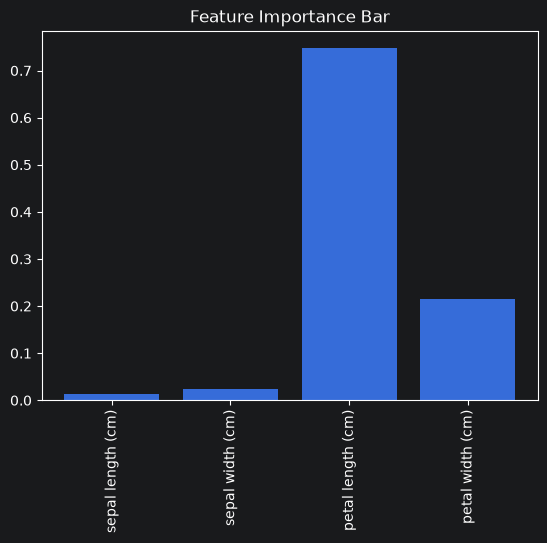

In [14]:
plt.bar(imp.index,imp)
plt.xticks(rotation=90)

plt.title('Feature Importance Bar')
plt.show()